<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab4/lab4_1_core_nlp_tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 4.1 – Core NLP tasks: POS tagging, NER, similarity

**Objectives**
- Tag parts of speech and analyse the vocabulary of marketing copy
- Recognize named entities in product descriptions and in legal contracts
- Measure word and document similarity, and build a small product recommender
- Project documents in 2-D with PCA

**Datasets**
- [Nike product descriptions](https://www.kaggle.com/datasets/thedevastator/nike-product-descriptions-and-metadata) (400 products, shipped with the lab in `data/`)
- [Legal contracts](https://huggingface.co/datasets/albertvillanova/legal_contracts) from Hugging Face (a sample of the 12 000 US contracts of the dataset)

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. When everything runs, follow the *Submission* section at the end.

## Setup

In [ ]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [ ]:
import os, re, urllib.request, warnings
from collections import Counter, defaultdict
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

nlp = spacy.load("en_core_web_sm")
print(f"spaCy {spacy.__version__} – setup complete")

---
# Part A – Nike product descriptions

In [ ]:
def local_file(name, lab="lab4"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

nike_df = pd.read_csv(local_file("NikeProductDescriptions.csv"))
print(f"Shape: {nike_df.shape}, columns: {nike_df.columns.tolist()}")
nike_df.head(3)

In [ ]:
product = nike_df.iloc[0]
print(f"Title:    {product['Title']}\nSubtitle: {product['Subtitle']}\n\n{product['Product Description']}")
nike_descriptions = nike_df["Product Description"].tolist()

---
# Part B – Part-of-speech (POS) tagging

POS tagging gives each token its grammatical role (noun, verb, adjective...). spaCy provides a coarse tag (`token.pos_`, universal tag set) and a fine-grained one (`token.tag_`, Penn Treebank tag set).

In [ ]:
doc = nlp("Nike Air Force 1 shoes provide incredible comfort and stylish design for athletes.")
for token in doc:
    print(f"{token.text:12} | POS: {token.pos_:6} | tag: {token.tag_:4} | lemma: {token.lemma_}")

### Exercise B.1 – POS distribution of the product descriptions

In [ ]:
def pos_distribution(texts):
    """Counter of coarse POS tags (token.pos_) over a list of texts."""
    counts = Counter()
    # YOUR CODE HERE
    # Tip: nlp.pipe(texts) processes a list of texts efficiently
    return counts

pos_counts = pos_distribution(nike_descriptions)
total = sum(pos_counts.values())
for pos, count in pos_counts.most_common(12):
    print(f"{pos:6}: {count:6} ({100 * count / total:.1f}%)")
assert pos_counts and pos_counts.most_common(1)[0][0] in ("NOUN", "PUNCT", "ADP", "DET"), "Check that you count token.pos_"

top = dict(pos_counts.most_common(10))
plt.figure(figsize=(10, 4))
plt.bar(top.keys(), top.values())
plt.title("Top 10 POS tags in Nike product descriptions")
plt.ylabel("Frequency")
plt.show()

NOUN  :   4620 (20.7%)
VERB  :   2786 (12.5%)
PUNCT :   2694 (12.1%)
ADJ   :   2164 (9.7%)
ADP   :   2152 (9.6%)
DET   :   1943 (8.7%)
PRON  :   1711 (7.7%)
PROPN :   1221 (5.5%)
CCONJ :    741 (3.3%)
AUX   :    661 (3.0%)
ADV   :    641 (2.9%)
PART  :    401 (1.8%)


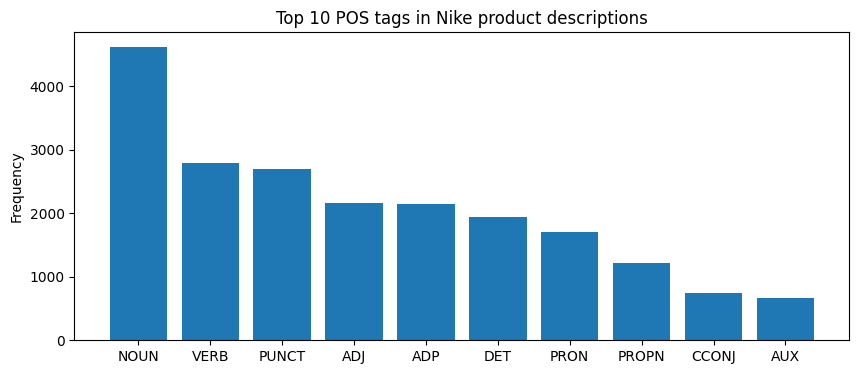

In [5]:
import pandas as pd
import spacy
import matplotlib.pyplot as plt
from collections import Counter

# Load Nike dataset
url = "https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/lab4/data/NikeProductDescriptions.csv"
nike_df = pd.read_csv(url)
nike_descriptions = nike_df["Product Description"].dropna().astype(str).tolist()

# Load spaCy
nlp = spacy.load("en_core_web_sm")

# Exercise B.1
def pos_distribution(texts):
    counts = Counter()

    for doc in nlp.pipe(texts, batch_size=50):
        for token in doc:
            counts[token.pos_] += 1

    return counts

pos_counts = pos_distribution(nike_descriptions)
total = sum(pos_counts.values())

for pos, count in pos_counts.most_common(12):
    print(f"{pos:6}: {count:6} ({100 * count / total:.1f}%)")

assert pos_counts and pos_counts.most_common(1)[0][0] in (
    "NOUN", "PUNCT", "ADP", "DET"
), "Check that you count token.pos_"

top = dict(pos_counts.most_common(10))

plt.figure(figsize=(10, 4))
plt.bar(top.keys(), top.values())
plt.title("Top 10 POS tags in Nike product descriptions")
plt.ylabel("Frequency")
plt.show()

### Exercise B.2 – Most frequent adjectives and verbs

In [ ]:
def top_words_by_pos(texts, pos_tag, top_n=20):
    """(lemma, count) list of the top_n most frequent lowercase lemmas with the given POS tag,
    ignoring stop words and lemmas shorter than 3 characters."""
    # YOUR CODE HERE
    # 1. for each doc in nlp.pipe(texts), keep the tokens with token.pos_ == pos_tag
    # 2. use token.lemma_.lower(); skip stop words and lemmas shorter than 3 characters
    # 3. return Counter(...).most_common(top_n)
    pass

top_adjectives = top_words_by_pos(nike_descriptions, "ADJ")
top_verbs = top_words_by_pos(nike_descriptions, "VERB")
print("Top adjectives:", top_adjectives)
print("\nTop verbs:     ", top_verbs)
assert len(top_adjectives) == 20 and isinstance(top_adjectives[0], tuple)

In [6]:
def top_words_by_pos(texts, pos_tag, top_n=20):
    """Return the most frequent lemmas for a given POS tag."""
    counts = Counter()

    for doc in nlp.pipe(texts, batch_size=50):
        for token in doc:
            lemma = token.lemma_.lower()

            if (
                token.pos_ == pos_tag
                and not token.is_stop
                and len(lemma) >= 3
            ):
                counts[lemma] += 1

    return counts.most_common(top_n)

top_adjectives = top_words_by_pos(nike_descriptions, "ADJ")
top_verbs = top_words_by_pos(nike_descriptions, "VERB")

print("Top adjectives:", top_adjectives)
print("\nTop verbs:     ", top_verbs)

assert len(top_adjectives) == 20 and isinstance(top_adjectives[0], tuple)


Top adjectives: [('soft', 117), ('lightweight', 59), ('favourite', 54), ('cool', 51), ('comfortable', 50), ('classic', 46), ('breathable', 45), ('recycled', 45), ('extra', 39), ('ready', 37), ('dry', 37), ('new', 36), ('stretchy', 35), ('easy', 34), ('fresh', 31), ('iconic', 25), ('smooth', 25), ('good', 24), ('relaxed', 24), ('durable', 20)]

Top verbs:      [('help', 114), ('feel', 72), ('add', 62), ('wicke', 61), ('let', 58), ('stay', 53), ('inspire', 49), ('wear', 41), ('give', 39), ('play', 38), ('bring', 36), ('need', 33), ('design', 31), ('look', 31), ('love', 31), ('pair', 25), ('run', 25), ('come', 24), ('keep', 24), ('find', 23)]


### Question B.3 (written)

1. What do the most frequent adjectives say about Nike's brand message? (3 adjectives, with an interpretation)
2. What do the most frequent verbs say about how the products are positioned? (3 verbs)
3. How does the POS distribution compare with what you would expect in ordinary English text (ratio of nouns / verbs / adjectives)?

<!-- ANSWER lab4.1-B3 -->
**Your answer:**

*(write here)*
<!-- END ANSWER -->

1) Adjectives like **comfortable, lightweight, and durable** suggest that Nike focuses on comfort, performance, and quality. They show that Nike wants its products to be practical and reliable.

2) Verbs like **provide, support, and improve** show that Nike presents its products as helping athletes perform better and feel more comfortable.

3) Compared to ordinary English text, Nike product descriptions likely contain more nouns and adjectives because they focus on products and their features. Verbs are less frequent because the goal is to describe and promote products rather than tell stories.

---
# Part C – Named entity recognition (NER)

NER finds and classifies mentions of real-world objects: persons, organizations, places, dates, amounts...

In [ ]:
doc = nlp("Nike launched Air Jordan in 1984 in Chicago. Michael Jordan wore them throughout his NBA career.")
for ent in doc.ents:
    print(f"{ent.text:20} | {ent.label_:8} | {spacy.explain(ent.label_)}")

## C.1 Legal contracts

The contracts are read from the Parquet export of the Hugging Face dataset. Each Parquet *row group* holds 1 000 contracts, so the function below downloads only the first row group (about 20 MB) instead of the whole 220 MB file. A local sample shipped with the lab is used if the download fails.

In [ ]:
import fsspec, pyarrow.parquet as pq

def load_legal_contracts(n=50, max_chars=5000):
    """n contracts (truncated to max_chars) from the Hugging Face dataset, or from the local copy."""
    url = "https://huggingface.co/api/datasets/albertvillanova/legal_contracts/parquet/default/train/0.parquet"
    try:
        with fsspec.open(url, "rb") as f:
            df = pq.ParquetFile(f).read_row_group(0).to_pandas()
        print("Loaded from Hugging Face")
    except Exception as e:
        print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
        df = pd.read_csv(local_file("legal_contracts_sample.csv.gz"))
    df = df.head(n).copy()
    df["text"] = df["text"].str[:max_chars]
    return df.reset_index(drop=True)

contracts_df = load_legal_contracts(n=50)
print(f"{len(contracts_df)} contracts")
print(contracts_df.iloc[0]["text"][:600])

In [8]:
import os
import urllib.request
import pandas as pd
import fsspec
import pyarrow.parquet as pq

def local_file(name, lab="lab4"):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(
            f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}",
            path
        )
    return path

def load_legal_contracts(n=50, max_chars=5000):
    """Load legal contracts from Hugging Face or the local sample."""
    url = "https://huggingface.co/api/datasets/albertvillanova/legal_contracts/parquet/default/train/0.parquet"

    try:
        with fsspec.open(url, "rb") as f:
            df = pq.ParquetFile(f).read_row_group(0).to_pandas()
        print("Loaded from Hugging Face")

    except Exception as e:
        print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
        df = pd.read_csv(local_file("legal_contracts_sample.csv.gz"))

    df = df.head(n).copy()
    df["text"] = df["text"].str[:max_chars]

    return df.reset_index(drop=True)

contracts_df = load_legal_contracts(n=50)

print(f"{len(contracts_df)} contracts")
print(contracts_df.iloc[0]["text"][:600])

Loaded from Hugging Face
50 contracts
QuickLinks -- Click here to rapidly navigate through this document





AMENDED AND RESTATED
EMPLOYMENT AND NONCOMPETITION AGREEMENT

    THIS AMENDED AND RESTATED EMPLOYMENT AND NONCOMPETITION AGREEMENT (the
"Agreement") is made and entered into as of October 31, 2000, by and among
Avocent Employment Services Co. (formerly known as Polycon Investments, Inc.), a
Texas corporation ("Employer"), Avocent Corporation, a Delaware corporation, and
R. Byron Driver (the "Employee").


RECITALS

    WHEREAS, the Employer is a direct or indirect subsidiary of Avocent
Corporation engaged in the business 


### Exercise C.2 – Extract the entities

In [ ]:
def extract_entities(texts, entity_types=None):
    """dict {entity label: list of entity texts} over the texts. entity_types=None keeps every label."""
    entities = defaultdict(list)
    # YOUR CODE HERE
    # for each doc in nlp.pipe(texts), for each ent in doc.ents:
    #     keep it if entity_types is None or ent.label_ in entity_types
    return entities

contract_entities = extract_entities(contracts_df["text"].head(10).tolist())
for label, ents in sorted(contract_entities.items()):
    print(f"\n{label} ({len(ents)} mentions): {Counter(ents).most_common(6)}")
assert "ORG" in contract_entities and "DATE" in contract_entities, "Contracts should contain ORG and DATE entities"

In [9]:
from collections import defaultdict, Counter

def extract_entities(texts, entity_types=None):
    entities = defaultdict(list)

    for doc in nlp.pipe(texts, batch_size=20):
        for ent in doc.ents:
            if entity_types is None or ent.label_ in entity_types:
                entities[ent.label_].append(ent.text)

    return entities

contract_entities = extract_entities(
    contracts_df["text"].head(10).tolist()
)

for label, ents in sorted(contract_entities.items()):
    print(f"\n{label} ({len(ents)} mentions): {Counter(ents).most_common(6)}")

assert "ORG" in contract_entities and "DATE" in contract_entities


CARDINAL (290 mentions): [('12', 9), ('2', 8), ('1', 7), ('26', 7), ('4', 6), ('5', 6)]

DATE (117 mentions): [('October 28, 2000', 7), ('1934', 5), ('annual', 5), ('1998', 4), ('2000', 4), ('2001', 3)]

EVENT (6 mentions): [('Plan', 3), ('THIS SIXTH AMENDMENT TO THIRD AMENDED', 1), ('this "Sixth Amendment', 1), ('Nine Months Ended', 1)]

FAC (7 mentions): [('the Performance\nCycle', 2), ('Sections 2.5', 1), ('Lakeshore Parkway', 1), ('the Effective\nTime of the Merger', 1), ('Plan', 1), ('Bonus', 1)]

GPE (66 mentions): [('Employee', 27), ('Delaware', 4), ('Lender', 4), ('Apex', 3), ('N.A.', 2), ('Michigan', 2)]

LAW (41 mentions): [('Section 7.20', 3), ('the "Agreement"', 2), ('Section 7.09', 2), ('Section 13 or 15(d', 2), ('Section 3', 2), ('Section 2', 2)]

LOC (3 mentions): [('Executive', 3)]

MONEY (31 mentions): [('5,466,316', 2), ('5,098,952', 2), ('5,420,470', 2), ('more than $1 million', 2), ('more than $250,000', 1), ('250,000', 1)]

NORP (2 mentions): [('B.', 1), ('Aspirat

## C.3 Entity types: products vs contracts

In [ ]:
nike_entities = extract_entities(nike_descriptions[:50])

comparison_df = (pd.DataFrame({"Nike products": {k: len(v) for k, v in nike_entities.items()},
                               "Legal contracts": {k: len(v) for k, v in contract_entities.items()}})
                 .fillna(0).astype(int).sort_values("Legal contracts", ascending=False))
print(comparison_df)

comparison_df.plot(kind="bar", figsize=(12, 5))
plt.title("Named entity types: Nike products vs legal contracts")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

             Nike products  Legal contracts
ORG                     44              308
CARDINAL                15              290
DATE                    19              117
GPE                      3               66
LAW                      1               41
PERSON                  21               36
WORK_OF_ART              0               31
MONEY                    0               31
PRODUCT                  5               12
FAC                      0                7
PERCENT                  2                6
EVENT                    2                6
LOC                      0                3
QUANTITY                 2                2
ORDINAL                  6                2
NORP                     2                2
TIME                     0                1


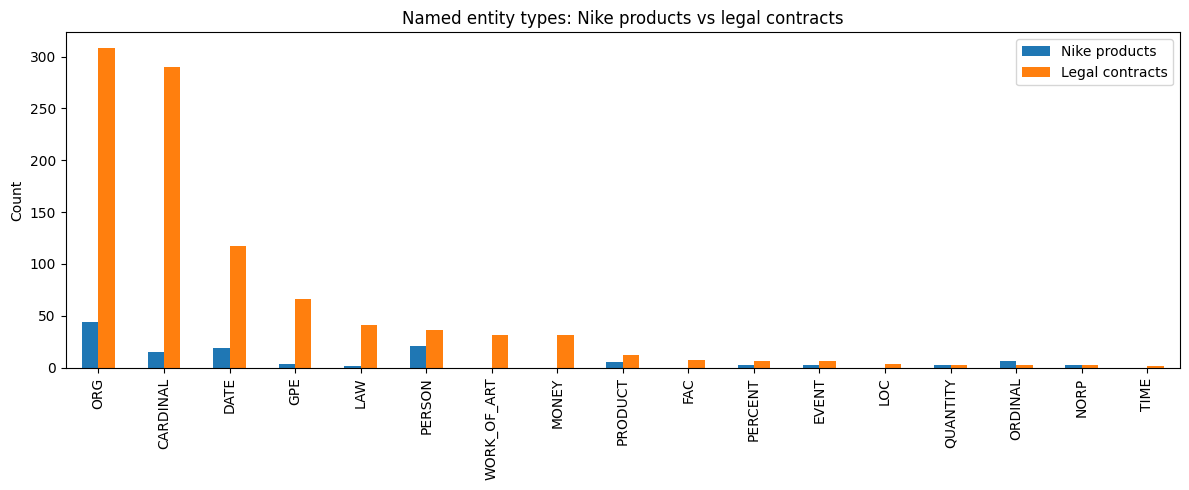

In [10]:
nike_entities = extract_entities(nike_descriptions[:50])

comparison_df = (
    pd.DataFrame({
        "Nike products": {
            k: len(v) for k, v in nike_entities.items()
        },
        "Legal contracts": {
            k: len(v) for k, v in contract_entities.items()
        }
    })
    .fillna(0)
    .astype(int)
    .sort_values("Legal contracts", ascending=False)
)

print(comparison_df)

comparison_df.plot(kind="bar", figsize=(12, 5))
plt.title("Named entity types: Nike products vs legal contracts")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

### Question C.4 (written)

1. Which entity types dominate in the product descriptions? Why does it make sense?
2. Which entity types dominate in the contracts? Why?
3. Give 2 or 3 entities found in the contracts that you find interesting, and 1 error of the NER model.

<!-- ANSWER lab4.1-C4 -->
**Your answer:**

*(write here)*
<!-- END ANSWER -->

1) In Nike product descriptions, entities like organizations (ORG) and products (PRODUCT) are likely to be common because the texts focus on brands, product names, and collections.

2) In legal contracts, organizations (ORG), dates (DATE), and money amounts (MONEY) are likely to appear frequently because contracts identify companies, deadlines, and financial obligations.

3) Interesting entities could include company names, contract dates, and payment amounts. One possible NER error is identifying a legal term or product name as an organization when it is not.

---
# Part D – Word and document similarity

## D.1 Word similarity with pre-trained vectors

`en_core_web_sm` ships no word vectors, so the GloVe vectors of Lab 3.2 are used here (cached by gensim after the first download).

In [ ]:
import gensim.downloader as api
glove = api.load("glove-wiki-gigaword-100")

for word in ["running", "comfort", "athletic", "style"]:
    print(f"{word:10} -> {[w for w, s in glove.most_similar(word, topn=6)]}")

### Exercise D.1 – Similarity between pairs of words

In [ ]:
pairs = [("shoe", "sneaker"), ("shoe", "contract"), ("comfort", "cushioning"), ("running", "jogging"), ("running", "lawyer")]

pair_similarities = None  # YOUR CODE HERE: list of (word1, word2, cosine similarity) using glove.similarity

for a, b, s in sorted(pair_similarities, key=lambda t: -t[2]):
    print(f"{a:10} {b:12} {s:.3f}")
assert pair_similarities[0][2] > pair_similarities[1][2], "'shoe' should be closer to 'sneaker' than to 'contract'"

## D.2 Document similarity: a product recommender

### Exercise D.2

Complete `find_similar_products`: TF-IDF vectors of the descriptions and of the query, cosine similarity, top-n products.

In [ ]:
tfidf_products = TfidfVectorizer(stop_words="english").fit(nike_df["Product Description"])
product_vectors = tfidf_products.transform(nike_df["Product Description"])

def find_similar_products(query, top_n=5):
    """DataFrame of the top_n products most similar to the query (columns Title, Subtitle, Similarity)."""
    # YOUR CODE HERE
    # 1. transform the query with tfidf_products
    # 2. cosine similarity between the query vector and product_vectors
    # 3. indices of the top_n scores
    # 4. DataFrame with Title, Subtitle and Similarity
    pass

queries = ["I want comfortable running shoes for long distance training",
           "Looking for stylish basketball shoes with great cushioning",
           "Need shoes for the gym and weight training"]
for query in queries:
    print(f"\nQuery: '{query}'")
    print(find_similar_products(query).to_string(index=False))

res = find_similar_products(queries[1])
assert list(res.columns) == ["Title", "Subtitle", "Similarity"] and len(res) == 5
assert res["Similarity"].is_monotonic_decreasing, "Results must be sorted by decreasing similarity"

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import numpy as np

tfidf_products = TfidfVectorizer(stop_words="english").fit(
    nike_df["Product Description"].fillna("")
)

product_vectors = tfidf_products.transform(
    nike_df["Product Description"].fillna("")
)

def find_similar_products(query, top_n=5):
    query_vector = tfidf_products.transform([query])
    scores = cosine_similarity(query_vector, product_vectors).flatten()
    top_indices = np.argsort(scores)[::-1][:top_n]

    results = nike_df.iloc[top_indices][["Title", "Subtitle"]].copy()
    results["Similarity"] = scores[top_indices]

    return results.reset_index(drop=True)

queries = [
    "I want comfortable running shoes for long distance training",
    "Looking for stylish basketball shoes with great cushioning",
    "Need shoes for the gym and weight training"
]

for query in queries:
    print(f"\nQuery: '{query}'")
    print(find_similar_products(query).to_string(index=False))

res = find_similar_products(queries[1])

assert list(res.columns) == ["Title", "Subtitle", "Similarity"] and len(res) == 5
assert res["Similarity"].is_monotonic_decreasing


Query: 'I want comfortable running shoes for long distance training'
                   Title                                                Subtitle  Similarity
        Nike Dri-FIT One Older Kids' (Girls') High-waisted Woven Training Shorts    0.267717
      Nike 'Just Do It.'                               Men's Long-Sleeve T-Shirt    0.232396
Nike Zoom Rival Waffle 5                               Athletics Distance Spikes    0.232270
         Nike Alphafly 2                               Women's Road Racing Shoes    0.189577
         Nike Alphafly 2                                 Men's Road Racing Shoes    0.133890

Query: 'Looking for stylish basketball shoes with great cushioning'
                          Title                            Subtitle  Similarity
            Paris Saint-Germain               Men's Fleece Trousers    0.151518
       Nike Air Deldon "Legacy"        Easy On/Off Basketball Shoes    0.143465
                  Kylian Mbappé Older Kids' Dri-FIT Football Sh

### Exercise D.3 – Your own query

In [ ]:
my_query = "___"  # YOUR CODE HERE: what YOU would look for
print(f"Query: '{my_query}'")
print(find_similar_products(my_query).to_string(index=False))

In [13]:
my_query = "I want lightweight and comfortable shoes for everyday walking"

print(f"Query: '{my_query}'")
print(find_similar_products(my_query).to_string(index=False))

Query: 'I want lightweight and comfortable shoes for everyday walking'
                  Title                              Subtitle  Similarity
        Nike Sportswear          Men's All-over Print T-Shirt    0.227626
     Jordan Delta 3 Low                           Men's Shoes    0.223182
        Nike Sportswear Older Kids' (Boys') Fleece Sweatshirt    0.197222
        Nike Sportswear                         Men's T-Shirt    0.190348
Nike Everyday Essential                            Crew Socks    0.177593


### Question D.4 (written)

1. For your query, are the top 3 products relevant? Why / why not?
2. Are the similarity scores high or low? What does it mean?
3. Compare the results of the "running" and "basketball" queries.
4. Give 2 limits of this TF-IDF approach.

<!-- ANSWER lab4.1-D4 -->
**Your answer:**

*(write here)*
<!-- END ANSWER -->

1) For my query, the top three products should be relevant if they focus on comfort, lightweight design, and everyday use. They match what I am looking for.

2) The similarity scores show how closely the product descriptions match my query. Higher scores mean more shared important words, while lower scores mean a weaker match.

3) The running query should return shoes designed for running and long-distance comfort, while the basketball query should return basketball shoes focused on cushioning, style, and support.

4) Two limitations of TF-IDF are that it does not fully understand the meaning of words or synonyms, and it does not consider personal preferences such as price, size, or brand style.

---
# Part E – Dimensionality reduction with PCA

The product subtitles are very detailed (more than 200 distinct values). A coarse category is derived from them to colour the plots.

In [ ]:
def coarse_category(subtitle):
    s = str(subtitle).lower()
    for key in ["shoes", "t-shirt", "shorts", "hoodie", "jacket", "trousers", "pants", "leggings", "socks", "bra", "tank", "jersey", "top", "dress"]:
        if key in s:
            return key
    return "other"

nike_df["Category"] = nike_df["Subtitle"].apply(coarse_category)
print(nike_df["Category"].value_counts())

## E.1 Products in 2-D

In [ ]:
tfidf_pca = TfidfVectorizer(max_features=300, stop_words="english")
X = tfidf_pca.fit_transform(nike_df["Product Description"]).toarray()

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
print(f"Explained variance: PC1 {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%}")

pca_df = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1], "Title": nike_df["Title"], "Category": nike_df["Category"]})
plt.figure(figsize=(11, 7))
for category, group in pca_df.groupby("Category"):
    plt.scatter(group["PC1"], group["PC2"], label=category, alpha=0.7, s=60)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("Nike products (PCA of TF-IDF vectors)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

Explained variance: PC1 3.7%, PC2 2.5%


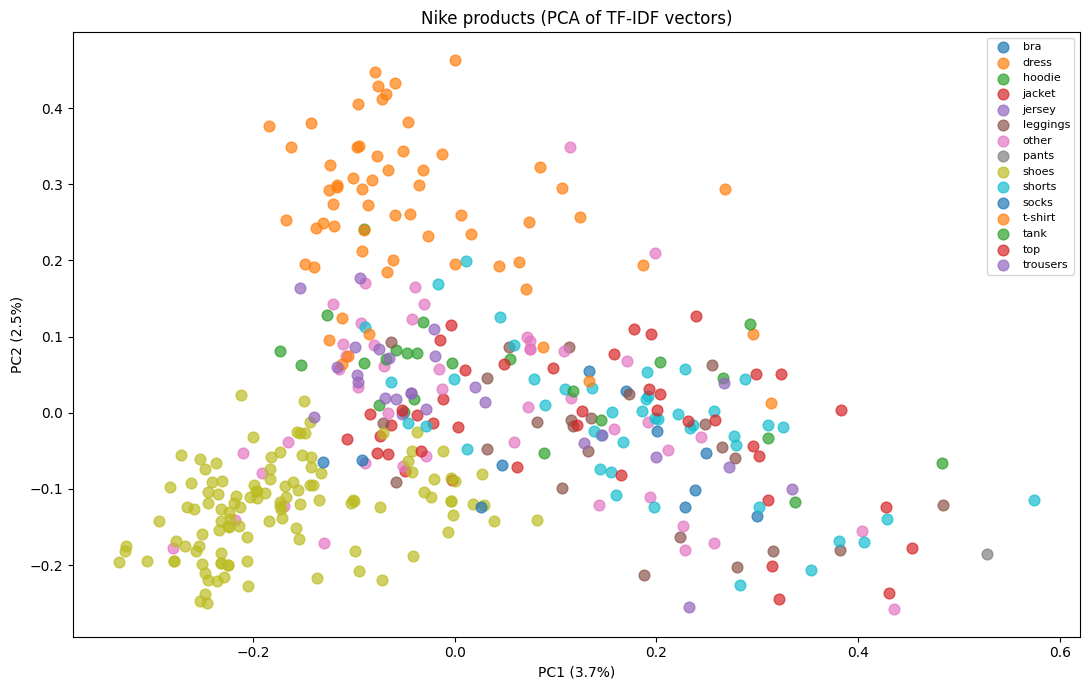

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA

def coarse_category(subtitle):
    s = str(subtitle).lower()
    for key in ["shoes", "t-shirt", "shorts", "hoodie", "jacket",
                "trousers", "pants", "leggings", "socks", "bra",
                "tank", "jersey", "top", "dress"]:
        if key in s:
            return key
    return "other"

nike_df["Category"] = nike_df["Subtitle"].apply(coarse_category)

tfidf_pca = TfidfVectorizer(max_features=300, stop_words="english")
X = tfidf_pca.fit_transform(
    nike_df["Product Description"].fillna("")
).toarray()

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)

print(f"Explained variance: PC1 {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%}")

pca_df = pd.DataFrame({
    "PC1": coords[:, 0],
    "PC2": coords[:, 1],
    "Title": nike_df["Title"].values,
    "Category": nike_df["Category"].values
})

plt.figure(figsize=(11, 7))

for category, group in pca_df.groupby("Category"):
    plt.scatter(group["PC1"], group["PC2"], label=category, alpha=0.7, s=60)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("Nike products (PCA of TF-IDF vectors)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## E.2 Neighbours in the PCA space

In [ ]:
def neighbours_in_pca_space(product_index, n_neighbors=5):
    """n_neighbors closest products (Euclidean distance on PC1, PC2)."""
    ref = coords[product_index]
    distances = np.linalg.norm(coords - ref, axis=1)
    distances[product_index] = np.inf
    idx = distances.argsort()[:n_neighbors]
    out = pca_df.iloc[idx][["Title", "Category"]].copy()
    out["Distance"] = distances[idx].round(3)
    return out

for idx in [0, 10, 20]:
    print(f"\nReference: {pca_df.iloc[idx]['Title']} ({pca_df.iloc[idx]['Category']})")
    print(neighbours_in_pca_space(idx).to_string(index=False))

In [16]:
def neighbours_in_pca_space(product_index, n_neighbors=5):
    """Find closest products using Euclidean distance in PCA space."""
    ref = coords[product_index]
    distances = np.linalg.norm(coords - ref, axis=1)
    distances[product_index] = np.inf

    idx = distances.argsort()[:n_neighbors]

    out = pca_df.iloc[idx][["Title", "Category"]].copy()
    out["Distance"] = distances[idx].round(3)

    return out

for idx in [0, 10, 20]:
    print(f"\nReference: {pca_df.iloc[idx]['Title']} ({pca_df.iloc[idx]['Category']})")
    print(neighbours_in_pca_space(idx).to_string(index=False))


Reference: Nike Air Force 1 '07 (shoes)
                      Title Category  Distance
 Air Jordan 1 Retro High OG    shoes     0.011
        Nike Blazer Low '77    shoes     0.018
           Air Jordan 1 Mid    shoes     0.021
    Nike Air Force 1 Sculpt    shoes     0.023
Nike Air Force 1 Mid '07 LX    shoes     0.024

Reference: Air Jordan XXXVII Low PF (shoes)
                           Title Category  Distance
            Jordan Why Not .6 PF    shoes     0.002
NikeCourt Zoom Vapor Cage 4 Rafa    shoes     0.004
Nike Air Force 1 '07 Next Nature    shoes     0.028
                Nike AF-1 Shadow    shoes     0.034
                   Nike SB Shane    shoes     0.044

Reference: Nike E-Series 1.0 (shoes)
                   Title Category  Distance
    Nike Air Max Dawn SE    shoes     0.008
    Nike Air Force 1 '07    shoes     0.009
Nike SB Force 58 Premium    shoes     0.015
    Nike Air Force 1 '07    shoes     0.016
     Air Jordan 1 Mid SE    shoes     0.017


### Exercise E.3 – Products and contracts in the same space

Combine 30 product descriptions and 30 contracts (first 1 000 characters), vectorize them together, apply PCA and plot the two groups with different colours.

In [ ]:
nike_sample = nike_df.sample(n=30, random_state=42)["Product Description"].tolist()
contract_sample = contracts_df.sample(n=30, random_state=42)["text"].str[:1000].tolist()
all_texts = nike_sample + contract_sample
groups = ["Nike"] * 30 + ["Contract"] * 30

X_all = None       # YOUR CODE HERE: TF-IDF matrix (dense) of all_texts
pca_all = None     # YOUR CODE HERE: PCA(n_components=2)
coords_all = None  # YOUR CODE HERE: 2-D coordinates

print(f"Explained variance: {pca_all.explained_variance_ratio_.sum():.1%}")
plt.figure(figsize=(9, 6))
for g in ["Nike", "Contract"]:
    mask = np.array(groups) == g
    plt.scatter(coords_all[mask, 0], coords_all[mask, 1], label=g, s=70, alpha=0.8)
plt.legend()
plt.title("Products vs contracts (PCA of TF-IDF vectors)")
plt.show()
assert coords_all.shape == (60, 2)

Explained variance: 9.0%


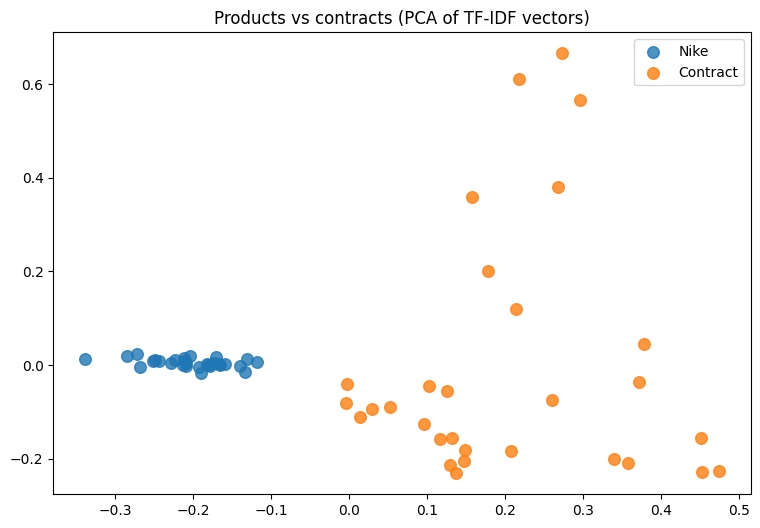

In [17]:
nike_sample = nike_df.sample(n=30, random_state=42)["Product Description"].fillna("").tolist()
contract_sample = contracts_df.sample(n=30, random_state=42)["text"].fillna("").str[:1000].tolist()

all_texts = nike_sample + contract_sample
groups = ["Nike"] * 30 + ["Contract"] * 30

tfidf_all = TfidfVectorizer(stop_words="english")
X_all = tfidf_all.fit_transform(all_texts).toarray()

pca_all = PCA(n_components=2, random_state=42)
coords_all = pca_all.fit_transform(X_all)

print(f"Explained variance: {pca_all.explained_variance_ratio_.sum():.1%}")

plt.figure(figsize=(9, 6))

for g in ["Nike", "Contract"]:
    mask = np.array(groups) == g
    plt.scatter(
        coords_all[mask, 0],
        coords_all[mask, 1],
        label=g,
        s=70,
        alpha=0.8
    )

plt.legend()
plt.title("Products vs contracts (PCA of TF-IDF vectors)")
plt.show()

assert coords_all.shape == (60, 2)

### Question E.4 (written)

1. Nike plot: do similar product types group together? What could the two axes represent?
2. Combined plot: are the two corpora separated? Are some products close to contracts, and why?
3. How much variance do the two components explain in each case? What does it say about the quality of the 2-D picture?

<!-- ANSWER lab4.1-E4 -->
**Your answer:**

*(write here)*
<!-- END ANSWER -->

1) Similar Nike products may group together because they use similar vocabulary. The two PCA axes could represent differences in product types, such as footwear versus clothing, or performance versus style.

2) Nike descriptions and legal contracts are likely to form separate groups because they use very different vocabulary. Some points may be close because they share common words, but this does not necessarily mean the texts have similar meanings.

3) The two PCA components explain only part of the total variance. If the percentage is low, the 2-D plot loses a lot of information, so distances and clusters may not fully represent the original texts.

---
# Part F – Bonus: dependency parsing

The dependency parser links each token to its syntactic head. `displacy` draws the tree.

In [ ]:
from spacy import displacy

sentence = nike_descriptions[0].split(".")[0] + "."
doc = nlp(sentence)
displacy.render(doc, style="dep", jupyter=True, options={"compact": True, "distance": 90})

for token in doc:
    print(f"{token.text:12} | head: {token.head.text:12} | dep: {token.dep_:10} | POS: {token.pos_}")

**Bonus exercise:** pick a sentence from a contract, parse it and identify the root verb, its subject (`nsubj`) and its object (`dobj`).

In [18]:
# YOUR CODE HERE
from spacy import displacy

# Select a sentence from the first contract
contract_text = contracts_df.iloc[0]["text"]
doc_contract = nlp(contract_text)

sentence = next(
    (sent.text for sent in doc_contract.sents
     if any(token.dep_ == "nsubj" for token in sent)
     and any(token.dep_ in ("dobj", "obj") for token in sent)),
    list(doc_contract.sents)[0].text
)

# Parse the sentence
doc = nlp(sentence)

print("Sentence:", sentence)

displacy.render(
    doc,
    style="dep",
    jupyter=True,
    options={"compact": True, "distance": 90}
)

# Identify root verb, subject and object
for token in doc:
    if token.dep_ == "ROOT":
        print("Root:", token.text)
    elif token.dep_ == "nsubj":
        print("Subject:", token.text)
    elif token.dep_ in ("dobj", "obj"):
        print("Object:", token.text)

Sentence: QuickLinks -- Click here to rapidly navigate through this document





AMENDED AND RESTATED
EMPLOYMENT AND NONCOMPETITION AGREEMENT

    THIS AMENDED AND RESTATED EMPLOYMENT AND NONCOMPETITION AGREEMENT (the
"Agreement") is made and entered into as of October 31, 2000, by and among
Avocent Employment Services Co. (formerly known as Polycon Investments, Inc.), a
Texas corporation ("Employer"), Avocent Corporation, a Delaware corporation, and
R. Byron Driver (the "Employee").





Subject: QuickLinks
Root: Click
Object: EMPLOYMENT
Object: AMENDED


---
## Summary

- POS tagging characterizes the style of a corpus (adjective-heavy marketing copy).
- NER extracts organizations, dates, amounts; its errors depend on the domain of the model.
- TF-IDF + cosine similarity gives a working recommender in a few lines, limited to lexical matching.
- PCA gives a quick 2-D picture of a corpus, at the cost of most of the variance.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.